In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("Food delivery.csv")
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [4]:
df.shape

(45593, 20)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [6]:
df['Weatherconditions'].value_counts()

Weatherconditions
conditions Fog           7654
conditions Stormy        7586
conditions Cloudy        7536
conditions Sandstorms    7495
conditions Windy         7422
conditions Sunny         7284
conditions NaN            616
Name: count, dtype: int64

In [7]:
df[df['Weatherconditions']=='conditions NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
74,0xa9f,BANGRES13DEL01,NaN,NaN,12.935662,77.614130,12.975662,77.654130,11-03-2022,NaN,15:30:00,conditions NaN,NaN,1,Drinks,scooter,0,No,Metropolitian,(min) 19
120,0x6e2,VADRES06DEL01,NaN,NaN,22.312790,73.170283,22.422790,73.280283,02-04-2022,NaN,18:25:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25
250,0x1b50,PUNERES16DEL01,NaN,NaN,18.536718,73.830327,18.646718,73.940327,08-03-2022,NaN,21:25:00,conditions NaN,NaN,3,Buffet,motorcycle,1,Yes,Urban,(min) 43
348,0x4c1,BANGRES13DEL02,NaN,NaN,12.935662,77.614130,13.065662,77.744130,02-03-2022,NaN,00:05:00,conditions NaN,NaN,3,Drinks,scooter,1,No,Metropolitian,(min) 26
425,0xc003,DEHRES13DEL02,NaN,NaN,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,22:30:00,conditions NaN,NaN,3,Snack,scooter,1,No,Metropolitian,(min) 20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45332,0x2950,VADRES04DEL02,50,6,0.000000,0.000000,0.020000,0.020000,19-03-2022,NaN,10:40:00,conditions NaN,NaN,3,Drinks,electric_scooter,1,No,Urban,(min) 28
45394,0xdc4,RANCHIRES02DEL03,NaN,NaN,0.000000,0.000000,0.030000,0.030000,05-03-2022,NaN,17:25:00,conditions NaN,NaN,3,Buffet,bicycle,1,No,Metropolitian,(min) 21
45504,0x461,BANGRES07DEL02,NaN,NaN,-12.978453,-77.643685,12.998453,77.663685,17-03-2022,NaN,09:30:00,conditions NaN,NaN,3,Meal,scooter,1,No,NaN,(min) 24
45518,0x863,INDORES05DEL01,NaN,NaN,22.727021,75.884167,22.737021,75.894167,19-03-2022,NaN,11:40:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25


In [8]:
temp="condition Fog"
temp.split(" ")[1] if pd.notnull(temp) else temp

'Fog'

In [9]:
# remove the first word conditions keep only the actual word

df['Weatherconditions']=df['Weatherconditions'].apply(lambda temp: temp.split(" ")[1] if pd.notnull(temp) else temp)

In [10]:
df['Weatherconditions']

0             Sunny
1            Stormy
2        Sandstorms
3             Sunny
4            Cloudy
            ...    
45588         Windy
45589         Windy
45590        Cloudy
45591        Cloudy
45592           Fog
Name: Weatherconditions, Length: 45593, dtype: str

In [11]:
# All text (object) columns

df.select_dtypes(include='str').columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival',
       'City', 'Time_taken(min)'],
      dtype='str')

In [12]:
# for every text columns: remove leading/trailing spaces, and turn the literal
# string 'NAN' (Not a real null) into an actual np.nan so pandas treat it as missing)

for col in df.select_dtypes(include='str').columns:
    df[col]=df[col].str.strip()
    df[col]=df[col].replace("NAN", np.nan)

In [13]:
# Target columns still stored as text, eg. "(min) 24"
type(df['Time_taken(min)'][0])

str

In [14]:
# Target columns: "(min) 24" --> 24 (int).

df['Time_taken(min)']=df['Time_taken(min)'].apply(lambda temp: int(temp.split(" ")[1]) if pd.notnull(temp) else temp)

In [15]:
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries']:
    df[col]=pd.to_numeric(df[col], errors='coerce')

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [17]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [18]:
# Rating should't exceed 5- clip any bad values(eg 6) back to the valid max. (53)
df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].clip(upper=5)

In [19]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.632567,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.331560,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [20]:
# Numeric columns: fill missing values with the median
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries']:
    df[col]=df[col].fillna(df[col].median())

In [21]:
cols = ['Weatherconditions', 'Road_traffic_density', 'Festival', 'City']
df[cols] = df[cols].replace('NaN', np.nan)

In [22]:
# Categorical columns: fill missing values with mode (most frequent category)
for col in ['Weatherconditions', 'Road_traffic_density', 'Festival', 'City']:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

# EDA

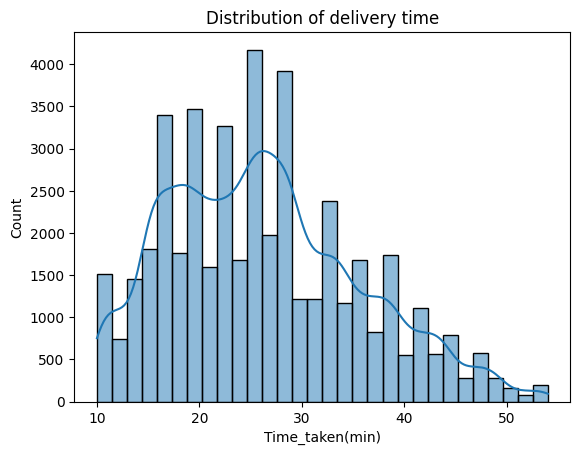

In [24]:
sns.histplot(df['Time_taken(min)'], bins=30, kde=True)
plt.title("Distribution of delivery time")
plt.show()

In [25]:
df.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.240000,27.0,8.396012
Jam,14143,31.176624,31.0,9.940904
Low,16078,21.464175,21.0,6.988438
Medium,10947,26.699644,27.0,8.560179


In [26]:
df.groupby('Weatherconditions')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Weatherconditions,,,,
Cloudy,7536,28.917330,28.0,10.084352
Fog,8270,28.739541,28.0,10.100816
Sandstorms,7495,25.875517,26.0,8.618434
Stormy,7586,25.870815,26.0,8.473273
Sunny,7284,21.856947,20.0,8.327210
Windy,7422,26.118836,26.0,8.615702


In [27]:
df.groupby('Festival')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Festival,,,,
No,44697,25.909256,25.0,9.052291
Yes,896,45.517857,45.0,4.001915


In [28]:
df.groupby('City')['Time_taken(min)'].agg(['count','mean'])

,count,mean
City,,
Metropolitian,35293,27.136486
Semi-Urban,164,49.731707
Urban,10136,22.984017


In [29]:
df.groupby('Type_of_vehicle')['Time_taken(min)'].agg(['count','mean'])

,count,mean
Type_of_vehicle,,
bicycle,68,26.426471
electric_scooter,3814,24.470110
motorcycle,26435,27.605674
scooter,15276,24.480754


In [30]:
df.groupby('Type_of_order')['Time_taken(min)'].agg(['count','mean'])

,count,mean
Type_of_order,,
Buffet,11280,26.283511
Drinks,11322,26.187953
Meal,11458,26.419270
Snack,11533,26.286309


In [31]:
df['Delivery_person_Age'].describe()

count    45593.000000
mean        29.584739
std          5.696333
min         15.000000
25%         25.000000
50%         30.000000
75%         34.000000
max         50.000000
Name: Delivery_person_Age, dtype: float64

<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

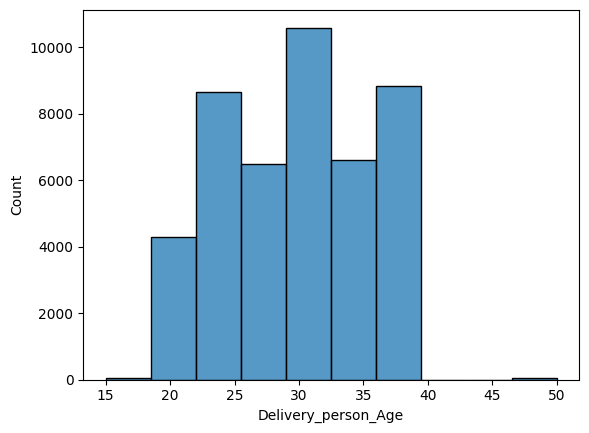

In [32]:
sns.histplot(df['Delivery_person_Age'],bins=10)

In [33]:
df[df['Delivery_person_Age']>40]['Delivery_person_Age'].shape

(53,)

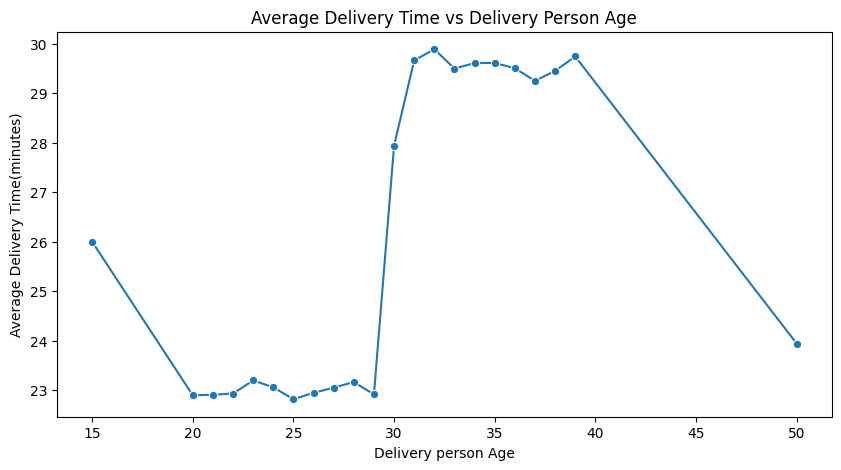

In [34]:
plt.figure(figsize=(10,5))
sns.lineplot(
    data=df,
    x="Delivery_person_Age",
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.title("Average Delivery Time vs Delivery Person Age")
plt.xlabel("Delivery person Age")
plt.ylabel("Average Delivery Time(minutes)")
plt.show()

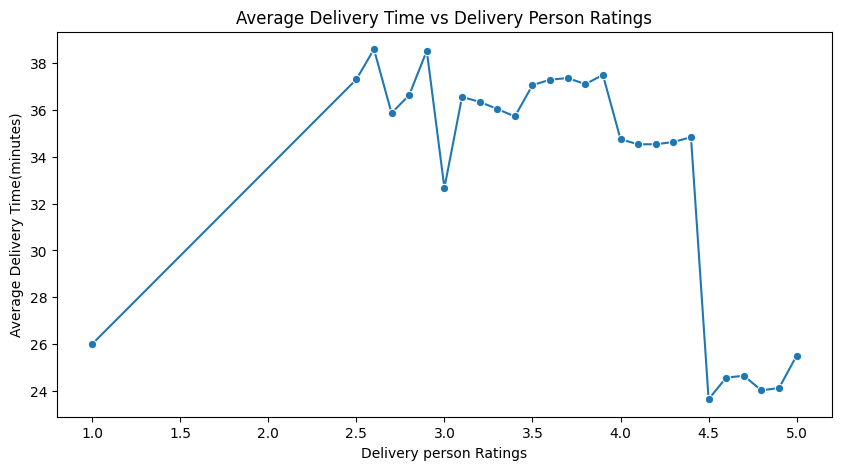

In [35]:
plt.figure(figsize=(10,5))
sns.lineplot(
    data=df,
    x="Delivery_person_Ratings",
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.title("Average Delivery Time vs Delivery Person Ratings")
plt.xlabel("Delivery person Ratings")
plt.ylabel("Average Delivery Time(minutes)")
plt.show()

In [36]:
df[df['Delivery_person_Ratings']<4].shape[0]/len(df)

0.02998267277871603

In [37]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='str')

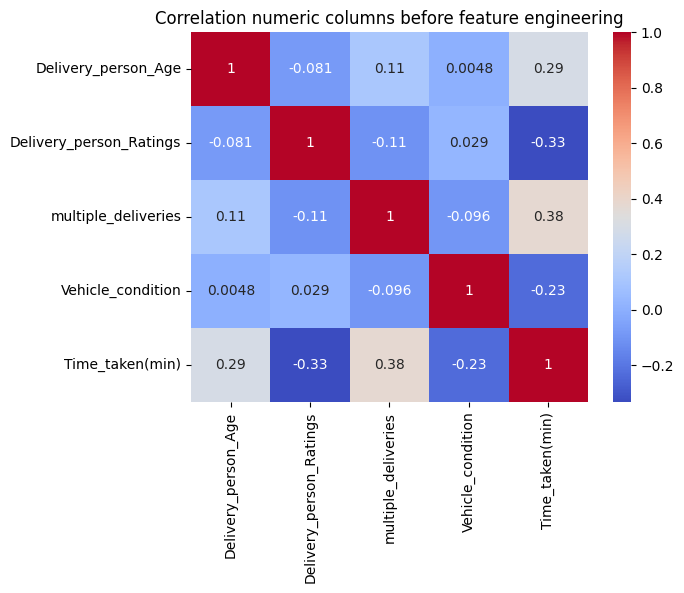

In [38]:
# correlation HeatMap

numeric_cols=['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries','Vehicle_condition','Time_taken(min)']
sns.heatmap(df[numeric_cols].corr(),annot=True,cmap='coolwarm')
plt.title('Correlation numeric columns before feature engineering')
plt.show()

In [39]:
hour=pd.to_datetime(df['Time_Order_picked'],format='%H:%M:%S', errors='coerce').dt.hour

In [40]:
hour.unique()

array([11, 19,  8, 18, 13, 21, 17, 22, 15,  9, 20, 12, 23, 14, 16, 10,  0],
      dtype=int32)

In [41]:
df.groupby(hour)['Time_taken(min)'].agg(['mean','median'])

,mean,median
Time_Order_picked,,
0,22.378030,21.0
8,19.544245,19.0
9,19.527805,19.0
10,19.512322,19.0
11,25.022727,25.0
12,26.981164,27.0
13,27.594493,27.0
14,27.741148,28.0
15,23.894912,25.0


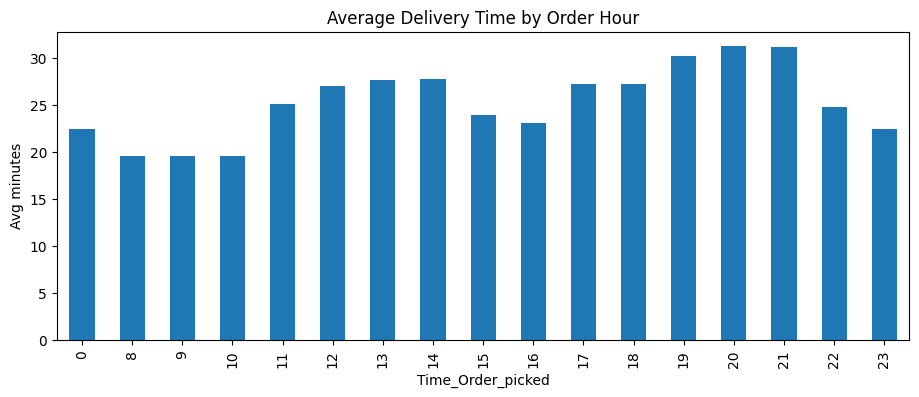

In [42]:
df.groupby(hour)['Time_taken(min)'].mean().plot(kind='bar',figsize=(11,4))
plt.title('Average Delivery Time by Order Hour')
plt.ylabel('Avg minutes')
plt.show()

# Feature Engineering
Haversine Formula use to calcute the Distance with the help of (latitude, longitude)


In [43]:
def calculate_series_distances(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    r=3956 if miles else 6371
    lat1, lon1, lat2, lon2=map(
        np.radians,[lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat=lat2-lat1
    dlon=lon2-lon1
    a=np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    c=2*np.arcsin(np.sqrt(a))
    return c*r


In [44]:
df['distance_km']=calculate_series_distances(df['Restaurant_latitude'],df['Restaurant_longitude'],df['Delivery_location_latitude'],df['Delivery_location_longitude'])

In [45]:
df['distance_km'].describe()

count    45593.000000
mean        99.303911
std       1099.731281
min          1.465067
25%          4.663493
50%          9.264281
75%         13.763977
max      19692.674606
Name: distance_km, dtype: float64

In [46]:
df[df['distance_km']>100]['distance_km'].describe()

count      431.000000
mean      9484.671093
std       6252.618252
min       2216.065794
25%       4434.856783
50%       5897.015762
75%      17132.390571
max      19692.674606
Name: distance_km, dtype: float64

In [47]:
df[df['distance_km']>100]

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
92,0xc042,AGRRES010DEL01,34.0,4.7,-27.163303,78.057044,27.233303,78.127044,16-02-2022,23:00:00,...,Sandstorms,Low,1,Drinks,scooter,0.0,No,Metropolitian,15,6048.631240
283,0xc044,AGRRES12DEL03,32.0,4.7,-27.165108,78.015053,27.225108,78.075053,13-02-2022,20:55:00,...,Sandstorms,Jam,2,Meal,scooter,1.0,No,Metropolitian,31,6047.919478
289,0x4db,PUNERES02DEL03,30.0,4.7,-18.551440,-73.804855,18.611440,73.864855,05-03-2022,NaN,...,Stormy,Jam,2,Meal,scooter,0.0,No,Urban,12,16612.239055
425,0xc003,DEHRES13DEL02,30.0,4.7,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,...,Fog,Low,3,Snack,scooter,1.0,No,Metropolitian,20,17744.205087
534,0x473,MYSRES07DEL03,30.0,4.7,-12.325461,-76.632278,12.385461,76.692278,03-03-2022,NaN,...,Fog,Low,3,Buffet,scooter,1.0,No,Metropolitian,16,17118.828366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44933,0xc0c2,AURGRES03DEL03,30.0,4.9,-19.874733,75.353942,19.904733,75.383942,15-02-2022,22:20:00,...,Fog,Low,1,Buffet,motorcycle,0.0,No,Metropolitian,15,4423.276011
45020,0x56b,PUNERES04DEL01,30.0,4.7,-18.514210,73.838429,18.524210,73.848429,21-03-2022,NaN,...,Fog,Low,3,Drinks,electric_scooter,1.0,No,Metropolitian,30,4118.484540
45108,0xc01b,GOARES18DEL01,30.0,4.7,-15.493950,-73.827423,15.563950,73.897423,16-02-2022,NaN,...,Windy,Jam,2,Meal,scooter,1.0,No,Urban,19,16560.629487
45182,0xc0c7,KNPRES16DEL02,30.0,4.0,-26.482581,80.315628,26.532581,80.365628,17-02-2022,22:25:00,...,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,34,5895.019482


In [48]:
df=df[df['distance_km']<100].reset_index(drop=True )

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  str    
 1   Delivery_person_ID           45162 non-null  str    
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  str    
 9   Time_Orderd                  45162 non-null  str    
 10  Time_Order_picked            45162 non-null  str    
 11  Weatherconditions            45162 non-null  str    
 12  Road_traffic_density         45162 non-null  str    
 13  Vehicle_condition          

In [50]:
# hour of day the order was placed(0-23)- kept continuous not binned(see notes below)
df['order_hour']=pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S', errors='coerce').dt.hour

In [51]:
df['order_hour'].unique()

array([11., 19.,  8., 18., 13., 21., 17., 20., 14.,  9., 22., 12., 23.,
       nan, 10., 16., 15.,  0.])

In [52]:
# A handful of uparseable time stamps become NaN hours fill with the median hour
df['order_hour']=df['order_hour'].fillna(df['order_hour'].median())

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  str    
 1   Delivery_person_ID           45162 non-null  str    
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  str    
 9   Time_Orderd                  45162 non-null  str    
 10  Time_Order_picked            45162 non-null  str    
 11  Weatherconditions            45162 non-null  str    
 12  Road_traffic_density         45162 non-null  str    
 13  Vehicle_condition          

In [54]:
feature=['Delivery_person_Age','Delivery_person_Ratings','distance_km','order_hour','Weatherconditions','Road_traffic_density','Vehicle_condition','Type_of_order','Type_of_vehicle','multiple_deliveries','Festival','City']

In [55]:
x=df[feature]
y=df['Time_taken(min)']

# Encoding

In [56]:
# Traffic density has a real order(low<mediam<high<jam) ordinal encoding 
traffic_mapping={
    'Low':0,
    'Medium':1,
    'High':2,
    'Jam':3,
}
x['Road_traffic_density']=x['Road_traffic_density'].map(traffic_mapping)

In [57]:
x['Road_traffic_density']

0        2
1        3
2        0
3        1
4        2
        ..
45157    2
45158    3
45159    0
45160    2
45161    1
Name: Road_traffic_density, Length: 45162, dtype: int64

In [58]:
# one hot encoding
x=pd.get_dummies(x, columns=['Type_of_order','Type_of_vehicle','Festival','City','Weatherconditions'], drop_first=True,dtype=int)

# Train / Test Split

In [59]:
from sklearn.model_selection import train_test_split

In [60]:
x_train, x_test, y_train,y_test=train_test_split(x,y,test_size=0.2, random_state=42)

# Feature Scaling

In [61]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [62]:
# fit the scaler on train only, then apply it to both - never fit on test data

x_train_scaled= scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [63]:
x_train_scaled

array([[-1.33517305,  0.51156709, -0.35171278, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 1.12628719,  0.19877778,  1.34683601, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [-0.80771728, -0.42680083,  1.30714108, ...,  2.23997508,
        -0.43645196, -0.44093773],
       ...,
       [ 1.65374296, -0.11401152, -0.67284161, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 0.77465001,  0.51156709, -1.18141457, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [ 0.77465001, -1.36516875,  0.65355565, ..., -0.44643354,
        -0.43645196, -0.44093773]], shape=(36129, 21))

In [64]:
# put back into data frame with original columns names index for readability

x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_test.columns, index=x_train.index)
x_test_scaled=pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)

In [65]:
import joblib
# save the fitted scaler
joblib.dump(scaler,"standard_scaler.pkl")

['standard_scaler.pkl']

# Model 1- Linear regression

In [66]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [67]:
lr.fit(x_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](21,)","[ 2.26,-2.18, 2.09,...,-1.01,-2.31,-0.97]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](21,)","['Delivery_person_Age','Delivery_person_Ratings','distance_km',..., 'Weatherconditions_Stormy','Weatherconditions_Sunny', 'Weatherconditions_Windy']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,21
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(21)


In [68]:
# one coefficient per feature (in the scaled space) - larger magnitude = bigger influence
lr.coef_

array([ 2.25707747, -2.17742371,  2.08640083, -0.54457378,  2.92036387,
       -1.7354634 ,  1.71928013, -0.07066725, -0.02591592, -0.01696524,
       -0.4410398 , -0.97325398, -1.21548077,  1.33110365,  0.58436762,
       -0.80964671,  0.08306582, -1.00542433, -1.01075931, -2.31276779,
       -0.96904815])

In [69]:
x_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='str')

In [70]:
from sklearn.metrics import r2_score, mean_squared_error

In [71]:
y_pred_test=lr.predict(x_test_scaled)

In [72]:
rmse_test=np.sqrt(mean_squared_error(y_test, y_pred_test))

In [73]:
r2_score(y_test, y_pred_test)

0.569315466760959

In [74]:
rmse_train=np.sqrt(mean_squared_error(y_train, lr.predict(x_train_scaled)))

In [75]:
r2_test=r2_score(y_train, lr.predict(x_train_scaled))

In [76]:
r2_train=r2_score(y_train, lr.predict(x_train_scaled))

In [77]:
print(rmse_train, r2_train)

6.043532429197743 0.5833426978406997


In [78]:
print(rmse_test, r2_test)

6.212510956097219 0.5833426978406997


# Model 2-Decision Tree

In [79]:
from sklearn.tree import DecisionTreeRegressor
dt=DecisionTreeRegressor(random_state=42)

In [80]:
dt.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [81]:
y_pred_dt=dt.predict(x_test_scaled)

In [82]:
# test Performance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
mse=mean_squared_error(y_test,dt.predict(x_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test, dt.predict(x_test_scaled))
print("dt rmse", rmse)
print("dt r2", r2)

dt rmse 5.491587519863505
dt r2 0.663472345116529


In [83]:
# now check train performance for comparison this is how we catching overfitting
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
mse=mean_squared_error(y_train,dt.predict(x_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train, dt.predict(x_train_scaled))
print("dt train rmse", rmse)
print("dt train r2", r2)

dt train rmse 0.0
dt train r2 1.0


# Model 3- Random Forest

In [84]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=100, random_state=42)

In [85]:
rf.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [86]:
# test Performance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
mse=mean_squared_error(y_test,rf.predict(x_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test, rf.predict(x_test_scaled))
print("rf rmse", rmse)
print("rf r2", r2)

rf rmse 4.028700960508738
rf r2 0.818884756316947


In [87]:
# train Performance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
mse=mean_squared_error(y_train,rf.predict(x_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train, rf.predict(x_train_scaled))
print("rf rmse", rmse)
print("rf r2", r2)

rf rmse 1.5058981863378045
rf r2 0.974130472037669


In [88]:
# hyperparameters

from sklearn.model_selection import RandomizedSearchCV
rf_param_dist={
    'n_estimators':[200,300,400,500],
    'max_depth':[10,15,20,25,None],
    'min_samples_leaf':[1,2,4],
    'min_samples_split':[2,5,10],
    'max_features':['sqrt','log2',0.5]
}
# sample 25 random combination instead of testing every combination

rf_search=RandomizedSearchCV(RandomForestRegressor(random_state=42),rf_param_dist,n_iter=25,cv=3,scoring='r2', random_state=42,n_jobs=-1)
rf_search.fit(x_train_scaled,y_train)
print("best params", rf_search.best_params_)
rf_best=rf_search.best_estimator_

best params {'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


In [89]:
r2_rf_tuned=r2_score(y_test, rf_best.predict(x_test_scaled))
rmse_rf_tuned=np.sqrt(mean_squared_error(y_test, rf_best.predict(x_test_scaled)))
print("tuned rf rmse", rmse_rf_tuned)
print("tuned rf r2", r2_rf_tuned)


tuned rf rmse 3.906264801714879
tuned rf r2 0.8297260146574709


In [90]:
rf.feature_importances_

array([0.10371796, 0.2085899 , 0.14027964, 0.01661365, 0.1248407 ,
       0.07130908, 0.12085823, 0.00569291, 0.00583098, 0.00567839,
       0.0020794 , 0.00288279, 0.00308543, 0.01310978, 0.00217802,
       0.00672798, 0.03260967, 0.02474661, 0.01899204, 0.06994284,
       0.020234  ])

In [91]:
x_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='str')

# Model 4- XGBoost

In [92]:
from xgboost import XGBRegressor
xgb=XGBRegressor(n_estimators=100, random_states=42)

In [93]:
xgb.fit(x_train_scaled, y_train)

c:\Users\swapn\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:11:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "random_states" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [94]:
# test
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
mse=mean_squared_error(y_test, xgb.predict(x_test_scaled))
rmse=np.sqrt(mse)
r2 = r2_score(y_test, xgb.predict(x_test_scaled))
print("xgb rmse", rmse)
print("xgb r2", r2)

xgb rmse 3.9989541593892377
xgb r2 0.8215494751930237


In [95]:
rgb_param_dist={
    'n_estimators':[300,500,800],
    'max_depth':[3,4,5,6,8],
    'learning_rate':[0.01, 0.03, 0.05, 0.1],
    'subsample':[0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':[0.7, 0.8, 0.9, 1.0],
    'reg_alpha':[0, 0.1, 0.5, 1],
    'reg_lambda':[1,1.5,2] 
}
xgb_search=RandomizedSearchCV(XGBRegressor(random_states=42),rgb_param_dist,n_iter=40, cv=3, scoring='r2', random_state=42)
xgb_search.fit(x_train_scaled, y_train)
print("best params", xgb_search.best_params_)
xgb_best=xgb_search.best_estimator_

c:\Users\swapn\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:11:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "random_states" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\swapn\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:11:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "random_states" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\swapn\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:11:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "random_states" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\swapn\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:11:03] WARNING: C:\actions-runner\_w

best params {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [96]:
# train 
r2_xgb_train=r2_score(y_train, xgb_best.predict(x_train_scaled))
rmse_xgb_train=np.sqrt(mean_squared_error(y_train, xgb_best.predict(x_train_scaled)))
print("xgb train rmse", rmse_xgb_train)
print("xgb train r2", r2_xgb_train)

xgb train rmse 3.680296893997318
xgb train r2 0.8454877138137817


In [97]:
# test
r2_xgb_test=r2_score(y_test, xgb_best.predict(x_test_scaled))
rmse_xgb_test=np.sqrt(mean_squared_error(y_test, xgb_best.predict(x_test_scaled)))
print("xgb test rmse", rmse_xgb_test)
print("xgb test r2", r2_xgb_test)

xgb test rmse 3.9114870899157568
xgb test r2 0.8292704224586487


In [98]:
joblib.dump(xgb_best, "xgb_best.pkl")

['xgb_best.pkl']

In [99]:
model=joblib.load("standard_scaler.pkl")
model=joblib.load("xgb_best.pkl")

In [106]:
sample=x_test[0:3]
sample

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Road_traffic_density,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,...,Type_of_vehicle_motorcycle,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy
29851,39.0,4.6,11.007735,17.0,1,0,1.0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
32062,38.0,4.9,1.513073,10.0,0,1,1.0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
25859,22.0,4.3,16.852445,20.0,3,2,1.0,0,1,0,...,0,1,0,0,0,0,0,0,0,0


In [ ]:
sample_scaled=scaler.transform(sample)

In [102]:
predictions=model.predict(sample_scaled)

In [103]:
predictions

array([40.70719 , 19.142271, 38.626217], dtype=float32)

In [105]:
y_test[0:3].values

array([46, 19, 40])